# MediVision AI – Model Comparison (Google Colab Free, Resume-Safe)

This notebook compares the same five pretrained CNN architectures used in the original experiment:

1. EfficientNetB0
2. ResNet50
3. DenseNet121
4. MobileNetV2
5. Xception

**Important:** This version is designed for **Google Colab Free**. It runs **one model per session**, saves checkpoints/results to Google Drive, supports resuming after runtime interruption, and skips models that are already completed.

The experimental dataset, classes, image size, optimizer, loss, and two-stage transfer-learning/fine-tuning procedure are retained from the original comparison notebook.


In [1]:
# ============================================================
# 1. GOOGLE DRIVE + GPU + LIBRARIES
# ============================================================
from google.colab import drive
drive.mount("/content/drive")

import os
import gc
import json
import time
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError(
        "GPU is not enabled. In Colab select Runtime → Change runtime type → GPU, "
        "then reconnect and run this notebook."
    )

# Avoid unnecessary GPU memory reservation.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception:
        pass

# Enable mixed precision on supported GPUs to reduce memory use.
try:
    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy("mixed_float16")
    print("Mixed precision policy:", mixed_precision.global_policy())
except Exception as e:
    print("Mixed precision not enabled:", e)


Mounted at /content/drive
TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy: <DTypePolicy "mixed_float16">


In [2]:
# ============================================================
# 2. CONFIGURATION
# ============================================================
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

NUM_CLASSES = 3
CLASS_NAMES = ["COVID", "Normal", "Viral Pneumonia"]

INITIAL_LR = 1e-3
FINE_TUNE_LR = 1e-5

# Original experiment configuration:
INITIAL_EPOCHS = 10
FINE_TUNE_EPOCHS = 10

# Free-Colab safety:
# Set this to ONE model per session.
MODEL_TO_RUN = "EfficientNetB0"

MODEL_NAMES = [
    "EfficientNetB0",
    "ResNet50",
    "DenseNet121",
    "MobileNetV2",
    "Xception",
]

assert MODEL_TO_RUN in MODEL_NAMES

# Dataset already prepared in your Drive.
DATASET_DIR = "/content/drive/MyDrive/computervisionproject/dataset/processed_dataset"
TRAIN_DIR = os.path.join(DATASET_DIR, "train")
VAL_DIR = os.path.join(DATASET_DIR, "val")
TEST_DIR = os.path.join(DATASET_DIR, "test")

# ALL persistent experiment artifacts live in Drive.
COMPARISON_DIR = "/content/drive/MyDrive/computervisionproject/model_comparison"
os.makedirs(COMPARISON_DIR, exist_ok=True)

MODEL_DIR = os.path.join(COMPARISON_DIR, MODEL_TO_RUN)
os.makedirs(MODEL_DIR, exist_ok=True)

print("Model:", MODEL_TO_RUN)
print("Dataset:", DATASET_DIR)
print("Persistent results:", MODEL_DIR)


Model: EfficientNetB0
Dataset: /content/drive/MyDrive/computervisionproject/dataset/processed_dataset
Persistent results: /content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0


In [3]:
# ============================================================
# 3. VERIFY DATASET
# ============================================================
for directory in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    print("\nChecking:", directory)
    if not os.path.isdir(directory):
        raise FileNotFoundError(f"Dataset directory not found: {directory}")

    for class_name in CLASS_NAMES:
        class_path = os.path.join(directory, class_name)
        if not os.path.isdir(class_path):
            raise FileNotFoundError(f"Class directory not found: {class_path}")
        count = sum(
            os.path.isfile(os.path.join(class_path, f))
            for f in os.listdir(class_path)
        )
        print(f"  {class_name}: {count} images")

print("\nDataset verification complete.")



Checking: /content/drive/MyDrive/computervisionproject/dataset/processed_dataset/train
  COVID: 2892 images
  Normal: 8153 images
  Viral Pneumonia: 1076 images

Checking: /content/drive/MyDrive/computervisionproject/dataset/processed_dataset/val
  COVID: 361 images
  Normal: 1019 images
  Viral Pneumonia: 134 images

Checking: /content/drive/MyDrive/computervisionproject/dataset/processed_dataset/test
  COVID: 363 images
  Normal: 1020 images
  Viral Pneumonia: 135 images

Dataset verification complete.


In [4]:
# ============================================================
# 4. LOAD DATASETS
# ============================================================
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE

# Keep source datasets reusable. Cache is intentionally NOT used because
# caching the entire image dataset can consume the limited Colab RAM.
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())


Found 12121 files belonging to 3 classes.
Found 1514 files belonging to 3 classes.
Found 1518 files belonging to 3 classes.
Train batches: 379
Validation batches: 48
Test batches: 48


In [5]:
# ============================================================
# 5. COMMON AUGMENTATION
# ============================================================
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.10),
    ],
    name="common_augmentation"
)

print(data_augmentation)


<Sequential name=common_augmentation, built=False>


In [6]:
# ============================================================
# 6. MODEL-SPECIFIC PREPROCESSING
# ============================================================
def get_preprocess_function(model_name):
    if model_name == "EfficientNetB0":
        # Current Keras EfficientNet includes preprocessing/rescaling internally.
        return None
    if model_name == "ResNet50":
        return keras.applications.resnet50.preprocess_input
    if model_name == "DenseNet121":
        return keras.applications.densenet.preprocess_input
    if model_name == "MobileNetV2":
        return keras.applications.mobilenet_v2.preprocess_input
    if model_name == "Xception":
        return keras.applications.xception.preprocess_input
    raise ValueError(f"Unknown model: {model_name}")

print(
    MODEL_TO_RUN,
    "→",
    "Built-in preprocessing"
    if get_preprocess_function(MODEL_TO_RUN) is None
    else "ImageNet preprocess_input"
)


EfficientNetB0 → Built-in preprocessing


In [7]:
# ============================================================
# 7. BUILD MODEL
# ============================================================
def build_model(model_name):
    input_layer = keras.Input(shape=(*IMG_SIZE, 3), name="input_image")

    if model_name == "EfficientNetB0":
        backbone = keras.applications.EfficientNetB0(
            include_top=False, weights="imagenet",
            input_shape=(*IMG_SIZE, 3)
        )
    elif model_name == "ResNet50":
        backbone = keras.applications.ResNet50(
            include_top=False, weights="imagenet",
            input_shape=(*IMG_SIZE, 3)
        )
    elif model_name == "DenseNet121":
        backbone = keras.applications.DenseNet121(
            include_top=False, weights="imagenet",
            input_shape=(*IMG_SIZE, 3)
        )
    elif model_name == "MobileNetV2":
        backbone = keras.applications.MobileNetV2(
            include_top=False, weights="imagenet",
            input_shape=(*IMG_SIZE, 3)
        )
    elif model_name == "Xception":
        backbone = keras.applications.Xception(
            include_top=False, weights="imagenet",
            input_shape=(*IMG_SIZE, 3)
        )
    else:
        raise ValueError(f"Unknown model: {model_name}")

    backbone.trainable = False

    x = backbone(input_layer, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    # Keep final output float32 when mixed precision is active.
    output = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        dtype="float32",
        name="classification_head"
    )(x)

    model = keras.Model(
        inputs=input_layer,
        outputs=output,
        name=model_name
    )

    return model, backbone

model, backbone = build_model(MODEL_TO_RUN)
model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_head (Dense)     │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [8]:
# ============================================================
# 8. DATASET PREPARATION
# ============================================================
def prepare_datasets(model_name):
    preprocess_fn = get_preprocess_function(model_name)

    def augment(images, labels):
        images = tf.cast(images, tf.float32)
        images = data_augmentation(images, training=True)
        if preprocess_fn is not None:
            images = preprocess_fn(images)
        return images, labels

    def validation_preprocess(images, labels):
        images = tf.cast(images, tf.float32)
        if preprocess_fn is not None:
            images = preprocess_fn(images)
        return images, labels

    train_data = train_ds.map(augment, num_parallel_calls=AUTOTUNE)
    val_data = val_ds.map(validation_preprocess, num_parallel_calls=AUTOTUNE)
    test_data = test_ds.map(validation_preprocess, num_parallel_calls=AUTOTUNE)

    return (
        train_data.prefetch(AUTOTUNE),
        val_data.prefetch(AUTOTUNE),
        test_data.prefetch(AUTOTUNE),
    )

train_data, val_data, test_data = prepare_datasets(MODEL_TO_RUN)

for images, labels in train_data.take(1):
    print("Image batch:", images.shape)
    print("Labels:", labels.shape)
    print("dtype:", images.dtype)
    break


Image batch: (32, 224, 224, 3)
Labels: (32,)
dtype: <dtype: 'float16'>


In [9]:
# ============================================================
# 9. PERSISTENT PATHS + RESUME STATE
# ============================================================
STAGE1_BEST = os.path.join(MODEL_DIR, f"{MODEL_TO_RUN}_stage1_best.keras")
STAGE2_BEST = os.path.join(MODEL_DIR, f"{MODEL_TO_RUN}_stage2_best.keras")
FINAL_MODEL = os.path.join(MODEL_DIR, f"{MODEL_TO_RUN}_final.keras")
RESULTS_JSON = os.path.join(MODEL_DIR, "results.json")
HISTORY_JSON = os.path.join(MODEL_DIR, "history.json")
REPORT_TXT = os.path.join(MODEL_DIR, "classification_report.txt")
CM_CSV = os.path.join(MODEL_DIR, "confusion_matrix.csv")

BACKUP_STAGE1 = os.path.join(MODEL_DIR, "backup_stage1")
BACKUP_STAGE2 = os.path.join(MODEL_DIR, "backup_stage2")

print("Persistent paths:")
for p in [STAGE1_BEST, STAGE2_BEST, FINAL_MODEL, RESULTS_JSON]:
    print(p)


Persistent paths:
/content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/EfficientNetB0_stage1_best.keras
/content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/EfficientNetB0_stage2_best.keras
/content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/EfficientNetB0_final.keras
/content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/results.json


In [10]:
# ============================================================
# 10. CALLBACK FACTORY
# ============================================================
def create_callbacks(stage):
    if stage == "stage1":
        checkpoint_path = STAGE1_BEST
        backup_dir = BACKUP_STAGE1
    else:
        checkpoint_path = STAGE2_BEST
        backup_dir = BACKUP_STAGE2

    os.makedirs(backup_dir, exist_ok=True)

    return [
        keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            monitor="val_accuracy",
            save_best_only=True,
            mode="max",
            verbose=1
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=3,
            mode="max",
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2,
            min_lr=1e-7,
            verbose=1
        ),
        keras.callbacks.BackupAndRestore(
            backup_dir=backup_dir,
            delete_checkpoint=False
        ),
    ]


In [11]:
# ============================================================
# 11. STAGE 1 — TRANSFER LEARNING
# ============================================================
def compile_stage1(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=INITIAL_LR),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

compile_stage1(model)

stage1_start = time.time()

history_stage1 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=INITIAL_EPOCHS,
    callbacks=create_callbacks("stage1"),
    verbose=1
)

stage1_time = time.time() - stage1_start

print(f"Stage 1 time: {stage1_time/60:.2f} minutes")


Epoch 1/10
379/379 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7758 - loss: 0.5292
Epoch 1: val_accuracy improved from None to 0.85733, saving model to /content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/EfficientNetB0_stage1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/EfficientNetB0_stage1_best.keras
379/379 ━━━━━━━━━━━━━━━━━━━━ 2889s 7s/step - accuracy: 0.8350 - loss: 0.4096 - val_accuracy: 0.8573 - val_loss: 0.3478 - learning_rate: 0.0010
Epoch 2/10
379/379 ━━━━━━━━━━━━━━━━━━━━ 0s 570ms/step - accuracy: 0.8829 - loss: 0.3038
Epoch 2: val_accuracy improved from 0.85733 to 0.89300, saving model to /content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/EfficientNetB0_stage1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/EfficientNetB0_stage1_best.keras
379/379 ━━━━━━━━━━━━━━━━━━━━ 225s

In [12]:
# ============================================================
# 12. LOAD BEST STAGE 1 CHECKPOINT
# ============================================================
if os.path.exists(STAGE1_BEST):
    model = keras.models.load_model(STAGE1_BEST)
    backbone = model.get_layer(backbone.name)
    print("Loaded best Stage 1 checkpoint:", STAGE1_BEST)
else:
    raise FileNotFoundError("Stage 1 checkpoint was not created.")


Loaded best Stage 1 checkpoint: /content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/EfficientNetB0_stage1_best.keras


In [13]:
# ============================================================
# 13. STAGE 2 — FINE-TUNING
# ============================================================

# Unfreeze only the upper portion of the backbone.
# This reduces computation and helps preserve pretrained features.
backbone = model.get_layer(backbone.name)

backbone.trainable = True

# Freeze earlier layers; fine-tune the later layers.
fine_tune_fraction = 0.20
fine_tune_from = int(len(backbone.layers) * (1.0 - fine_tune_fraction))

for layer in backbone.layers[:fine_tune_from]:
    layer.trainable = False

for layer in backbone.layers[fine_tune_from:]:
    layer.trainable = True

# BatchNorm layers are kept frozen for stable fine-tuning.
for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile after changing trainable status
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=FINE_TUNE_LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# Count trainable parameters correctly
# ------------------------------------------------------------
trainable_count = sum(
    v.numpy().size for v in model.trainable_variables
)

print("Trainable parameters:", f"{trainable_count:,}")

stage2_start = time.time()

history_stage2 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=create_callbacks("stage2"),
    verbose=1
)

stage2_time = time.time() - stage2_start

print(f"Stage 2 time: {stage2_time/60:.2f} minutes")

Trainable parameters: 2,291,347
Epoch 1/10
379/379 ━━━━━━━━━━━━━━━━━━━━ 0s 632ms/step - accuracy: 0.9125 - loss: 0.2242
Epoch 1: val_accuracy improved from None to 0.91149, saving model to /content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/EfficientNetB0_stage2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/EfficientNetB0_stage2_best.keras
379/379 ━━━━━━━━━━━━━━━━━━━━ 334s 755ms/step - accuracy: 0.9156 - loss: 0.2198 - val_accuracy: 0.9115 - val_loss: 0.2256 - learning_rate: 1.0000e-05
Epoch 2/10
379/379 ━━━━━━━━━━━━━━━━━━━━ 0s 567ms/step - accuracy: 0.9238 - loss: 0.2051
Epoch 2: val_accuracy improved from 0.91149 to 0.92404, saving model to /content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/EfficientNetB0_stage2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/computervisionproject/model_comparison/EfficientNetB0/EfficientNetB0_stage2_bes

In [ ]:
# ============================================================
# 14. LOAD BEST FINE-TUNED CHECKPOINT
# ============================================================
if os.path.exists(STAGE2_BEST):
    model = keras.models.load_model(STAGE2_BEST)
    print("Loaded best Stage 2 checkpoint:", STAGE2_BEST)
else:
    raise FileNotFoundError("Stage 2 checkpoint was not created.")

# Save a stable final copy to Drive.
model.save(FINAL_MODEL)
print("Final model saved:", FINAL_MODEL)


In [ ]:
# ============================================================
# 15. EVALUATE MODEL
# ============================================================
eval_start = time.time()

test_loss, test_accuracy = model.evaluate(
    test_data,
    verbose=1
)

eval_time = time.time() - eval_start

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)
print(f"Evaluation time: {eval_time/60:.2f} minutes")


In [16]:
# ============================================================
# 16. DETAILED METRICS
# ============================================================
y_true = []
y_prob = []

for images, labels in test_data:
    probs = model.predict(images, verbose=0)
    y_true.extend(labels.numpy().tolist())
    y_prob.extend(probs.tolist())

y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

try:
    auc = roc_auc_score(
        y_true,
        y_prob,
        multi_class="ovr",
        average="weighted"
    )
except Exception as e:
    auc = None
    print("ROC-AUC unavailable:", e)

report = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

cm = confusion_matrix(y_true, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {auc if auc is not None else 'N/A'}")
print("\nClassification Report:\n")
print(report)


Accuracy : 0.9328
Precision: 0.9395
Recall   : 0.9328
F1 Score : 0.9341
ROC-AUC  : 0.9897144761324689

Classification Report:

                 precision    recall  f1-score   support

          COVID     0.8197    0.9642    0.8861       363
         Normal     0.9792    0.9216    0.9495      1020
Viral Pneumonia     0.9618    0.9333    0.9474       135

       accuracy                         0.9328      1518
      macro avg     0.9202    0.9397    0.9276      1518
   weighted avg     0.9395    0.9328    0.9341      1518



In [ ]:
# ============================================================
# 17. SAVE CONFUSION MATRIX + REPORT
# ============================================================
cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)
cm_df.to_csv(CM_CSV)

with open(REPORT_TXT, "w", encoding="utf-8") as f:
    f.write(report)

print("Classification report saved:", REPORT_TXT)
print("Confusion matrix saved:", CM_CSV)


In [ ]:
# ============================================================
# 18. SAVE TRAINING HISTORY
# ============================================================
def history_to_dict(history):
    if history is None:
        return {}
    return {
        key: [float(x) for x in values]
        for key, values in history.history.items()
    }

history_payload = {
    "stage1": history_to_dict(history_stage1),
    "stage2": history_to_dict(history_stage2),
}

with open(HISTORY_JSON, "w", encoding="utf-8") as f:
    json.dump(history_payload, f, indent=2)

print("History saved:", HISTORY_JSON)


In [ ]:
# ============================================================
# 19. SAVE FINAL RESULTS — ATOMIC JSON WRITE
# ============================================================
total_training_time = stage1_time + stage2_time

results = {
    "model": MODEL_TO_RUN,
    "classes": CLASS_NAMES,
    "image_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "initial_epochs": INITIAL_EPOCHS,
    "fine_tune_epochs": FINE_TUNE_EPOCHS,
    "initial_learning_rate": INITIAL_LR,
    "fine_tune_learning_rate": FINE_TUNE_LR,
    "test_loss": float(test_loss),
    "accuracy": float(accuracy),
    "precision_weighted": float(precision),
    "recall_weighted": float(recall),
    "f1_weighted": float(f1),
    "roc_auc_weighted_ovr": None if auc is None else float(auc),
    "stage1_time_seconds": float(stage1_time),
    "stage2_time_seconds": float(stage2_time),
    "total_training_time_seconds": float(total_training_time),
    "evaluation_time_seconds": float(eval_time),
    "final_model": FINAL_MODEL,
    "stage1_best": STAGE1_BEST,
    "stage2_best": STAGE2_BEST,
}

tmp_results = RESULTS_JSON + ".tmp"
with open(tmp_results, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)
os.replace(tmp_results, RESULTS_JSON)

print(json.dumps(results, indent=2))
print("\nResults saved:", RESULTS_JSON)


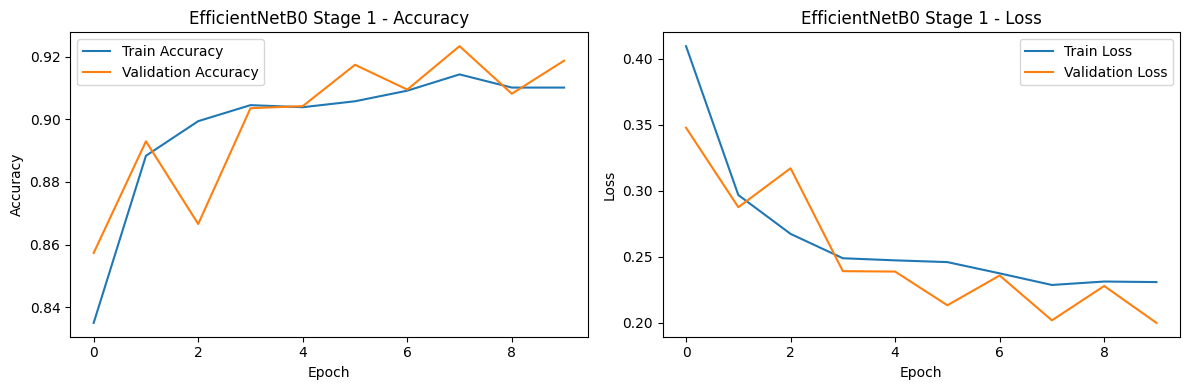

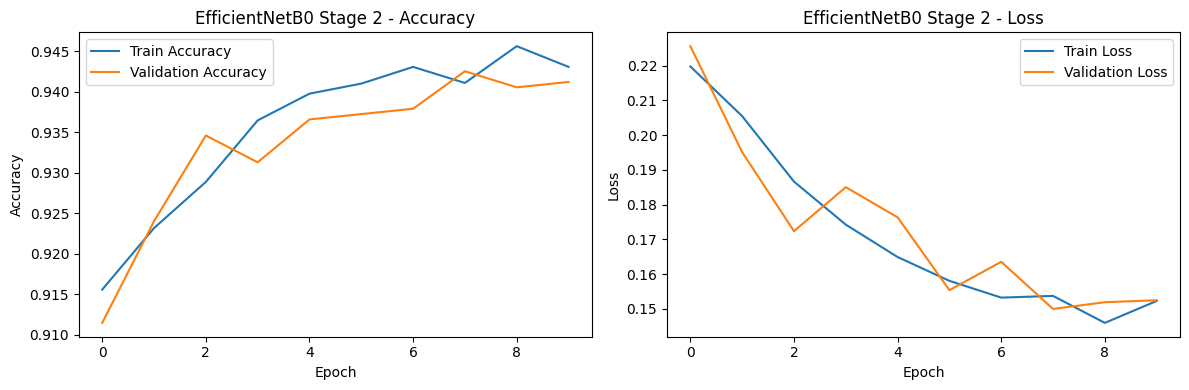

In [20]:
# ============================================================
# 20. PLOT TRAINING HISTORY
# ============================================================
def plot_history(history, title):
    if history is None or not history.history:
        return

    h = history.history

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(h.get("accuracy", []), label="Train Accuracy")
    plt.plot(h.get("val_accuracy", []), label="Validation Accuracy")
    plt.title(title + " - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(h.get("loss", []), label="Train Loss")
    plt.plot(h.get("val_loss", []), label="Validation Loss")
    plt.title(title + " - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history_stage1, MODEL_TO_RUN + " Stage 1")
plot_history(history_stage2, MODEL_TO_RUN + " Stage 2")


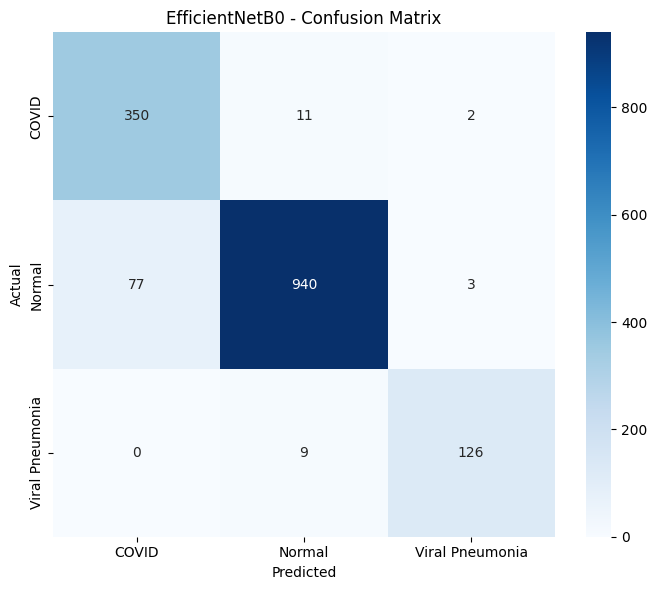

In [21]:
# ============================================================
# 21. CONFUSION MATRIX
# ============================================================
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title(f"{MODEL_TO_RUN} - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


## 22. Free-Colab Session Completion

When this model finishes, **do not run the next model in the same session**.

The following files are now stored in Google Drive:

- `*_stage1_best.keras`
- `*_stage2_best.keras`
- `*_final.keras`
- `results.json`
- `history.json`
- `classification_report.txt`
- `confusion_matrix.csv`

To continue, start a fresh Colab runtime and change only:

```python
MODEL_TO_RUN = "ResNet50"
```

Then run the notebook again.

Use the same procedure for:

- DenseNet121
- MobileNetV2
- Xception

Already completed models will be detected by the final comparison notebook below.


In [22]:
# ============================================================
# 23. FINAL COMPARISON — RUN ONLY AFTER ALL FIVE MODELS FINISH
# ============================================================
# This section does NOT train anything.
# It only reads results already saved in Google Drive.

comparison_rows = []

for model_name in MODEL_NAMES:
    result_file = os.path.join(
        COMPARISON_DIR,
        model_name,
        "results.json"
    )

    if not os.path.exists(result_file):
        print("NOT COMPLETED:", model_name)
        continue

    with open(result_file, "r", encoding="utf-8") as f:
        r = json.load(f)

    comparison_rows.append({
        "Model": model_name,
        "Accuracy": r.get("accuracy"),
        "Precision": r.get("precision_weighted"),
        "Recall": r.get("recall_weighted"),
        "F1 Score": r.get("f1_weighted"),
        "ROC-AUC": r.get("roc_auc_weighted_ovr"),
        "Training Time (min)": r.get("total_training_time_seconds", 0) / 60
    })

comparison_df = pd.DataFrame(comparison_rows)

if comparison_df.empty:
    print("No completed model results found yet.")
else:
    display(comparison_df)
    comparison_df.to_csv(
        os.path.join(COMPARISON_DIR, "model_comparison_summary.csv"),
        index=False
    )
    print("Summary saved to Drive.")


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (min)
0,EfficientNetB0,0.932806,0.939485,0.932806,0.934140,0.989714,125.107778
1,ResNet50,0.980896,0.981033,0.980896,0.980799,0.997973,79.190512
2,DenseNet121,0.949934,0.949682,0.949934,0.949548,0.988017,105.613639
3,MobileNetV2,0.959157,0.959228,0.959157,0.959188,0.994702,108.576812
4,Xception,0.964427,0.964486,0.964427,0.964086,0.994085,70.835859


Summary saved to Drive.


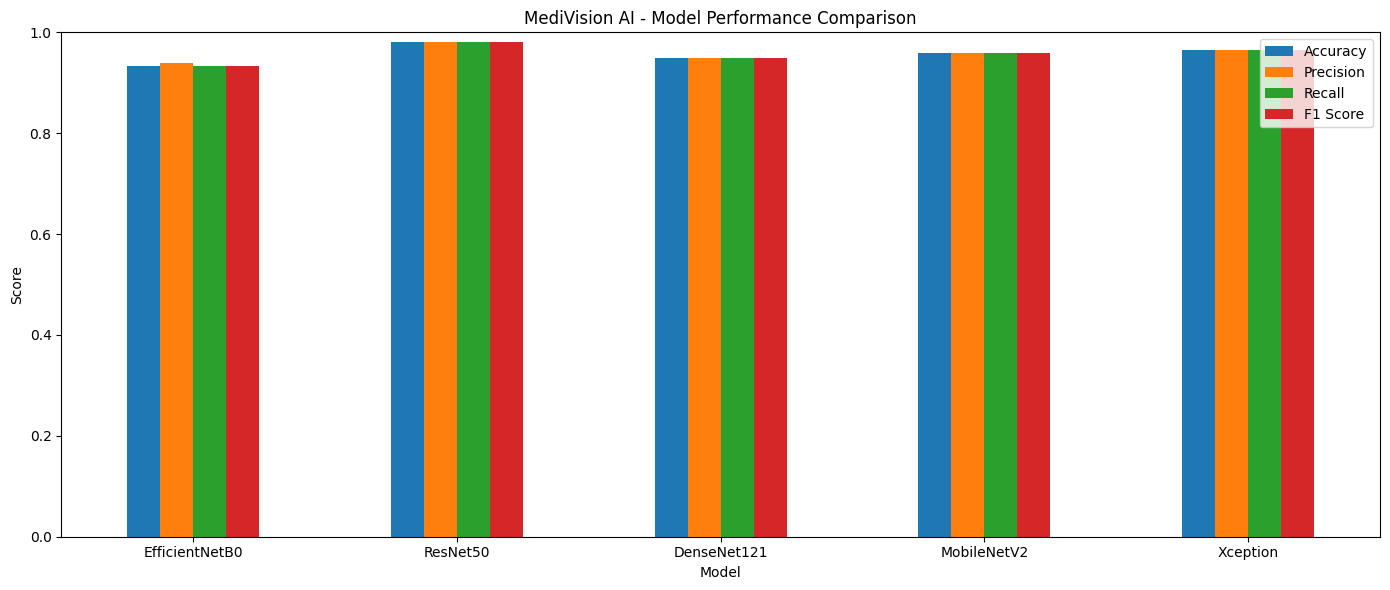

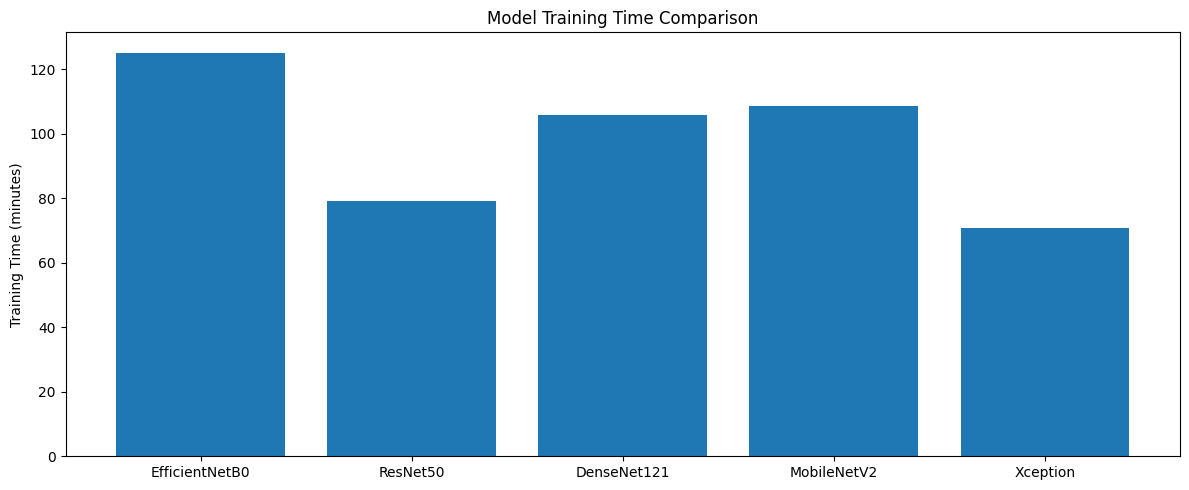

In [23]:
# ============================================================
# 24. COMPARISON VISUALIZATION
# ============================================================
if not comparison_df.empty:
    metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

    ax = comparison_df.set_index("Model")[metrics].plot(
        kind="bar",
        figsize=(14, 6)
    )
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.set_title("MediVision AI - Model Performance Comparison")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 5))
    plt.bar(
        comparison_df["Model"],
        comparison_df["Training Time (min)"]
    )
    plt.ylabel("Training Time (minutes)")
    plt.title("Model Training Time Comparison")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


In [24]:
# ============================================================
# 25. CHECKPOINT STATUS
# ============================================================
print("MODEL COMPLETION STATUS")
print("=" * 50)

for model_name in MODEL_NAMES:
    result_file = os.path.join(
        COMPARISON_DIR,
        model_name,
        "results.json"
    )
    final_model = os.path.join(
        COMPARISON_DIR,
        model_name,
        f"{model_name}_final.keras"
    )

    if os.path.exists(result_file) and os.path.exists(final_model):
        print(f"✓ {model_name}: COMPLETED")
    else:
        print(f"✗ {model_name}: NOT COMPLETED")


MODEL COMPLETION STATUS
✓ EfficientNetB0: COMPLETED
✓ ResNet50: COMPLETED
✓ DenseNet121: COMPLETED
✓ MobileNetV2: COMPLETED
✓ Xception: COMPLETED


## Notes for the experiment

- The five architectures are kept unchanged from the original comparison notebook.
- The dataset split remains the prepared `train / val / test` split.
- The class order remains `COVID / Normal / Viral Pneumonia`.
- The original 10 + 10 epoch configuration is retained.
- Early stopping can terminate training before the maximum epoch count.
- Each model is isolated into its own Google Drive folder.
- `BackupAndRestore` helps recover interrupted training state.
- The final comparison stage performs no training.
- Do not fabricate missing model results. If a model has not completed, the summary explicitly marks it as incomplete.
